# Première partie

## 1. Série temporelle : s = sin(x)

X : torch.Size([190, 10, 1]) | y : torch.Size([190, 1])
Train : 150 | Test : 40


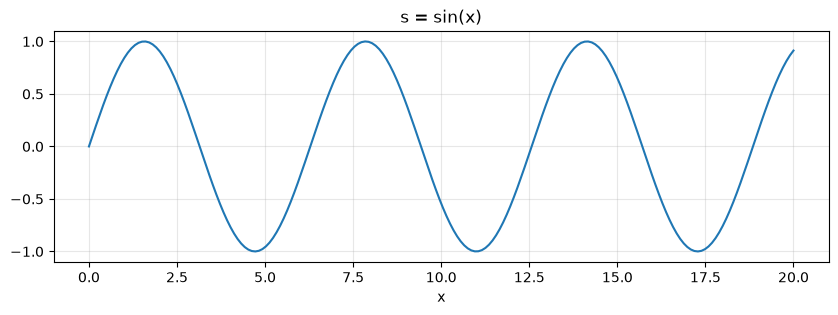

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10

X = torch.stack([serie[i:i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])
y = torch.stack([serie[i + longueur_sequence] for i in range(len(serie) - longueur_sequence)])

X = X.unsqueeze(-1)   # (190, 10, 1)
y = y.unsqueeze(-1)   # (190, 1)

X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X :", X.shape, "| y :", y.shape)
print("Train :", X_train.shape[0], "| Test :", X_test.shape[0])

plt.figure(figsize=(10, 3))
plt.plot(periode, serie)
plt.title("s = sin(x)")
plt.xlabel("x")
plt.grid(alpha=0.3)
plt.show()

In [2]:
def entrainer(modele, epochs=300, lr=0.01):
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)

    modele.train()
    for epoch in range(epochs):
        predictions = modele(X_train)
        perte = critere(predictions, y_train)

        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()

        if (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch + 1:3d} | Erreur : {perte.item():.6f}")

    modele.eval()
    with torch.no_grad():
        predictions = modele(X_test)
        erreur_test = critere(predictions, y_test).item()

    print(f"\nErreur de test : {erreur_test:.6f}")
    print(f"Valeur réelle  : {y_test[0].item():.4f}")
    print(f"Valeur prédite : {predictions[0].item():.4f}")
    return predictions, erreur_test


def tracer(predictions, nom):
    plt.figure(figsize=(12, 4))
    plt.plot(y_test.reshape(-1), label="Valeurs réelles", linewidth=2)
    plt.plot(predictions.reshape(-1), "--", label=f"Prédictions du {nom}", linewidth=2)
    plt.title(f"{nom} : valeurs réelles et prédictions")
    plt.xlabel("Indice de l'échantillon de test")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()


resultats = {}

## 2. Modèle RNN

Epoch  50 | Erreur : 0.001277
Epoch 100 | Erreur : 0.000504
Epoch 150 | Erreur : 0.000223
Epoch 200 | Erreur : 0.000103
Epoch 250 | Erreur : 0.000049
Epoch 300 | Erreur : 0.000025

Erreur de test : 0.000028
Valeur réelle  : -0.3639
Valeur prédite : -0.3601


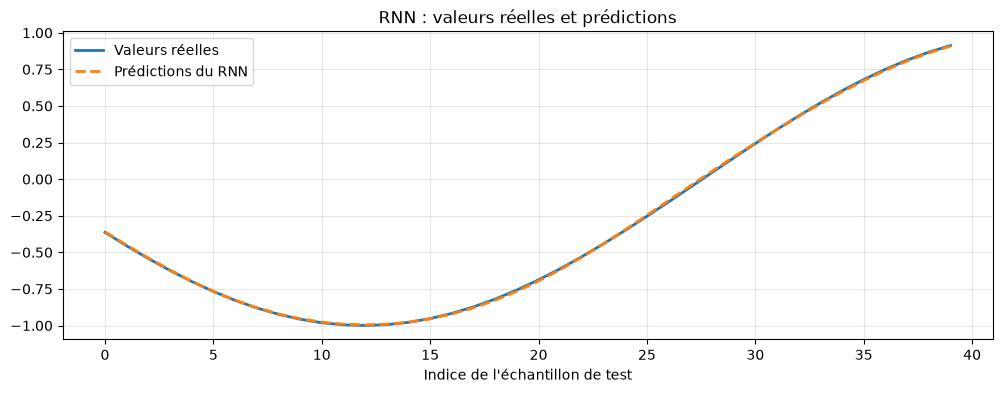

In [3]:
class SimpleRNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=16, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, _ = self.rnn(x)              # (B, 10, 16)
        return self.sortie(etats[:, -1, :])  # (B, 1)


torch.manual_seed(42)
predictions, resultats["RNN"] = entrainer(SimpleRNN())
tracer(predictions, "RNN")

## 3. Modèle LSTM

Epoch  50 | Erreur : 0.003562
Epoch 100 | Erreur : 0.000248
Epoch 150 | Erreur : 0.000043
Epoch 200 | Erreur : 0.000006
Epoch 250 | Erreur : 0.000004
Epoch 300 | Erreur : 0.000003

Erreur de test : 0.000003
Valeur réelle  : -0.3639
Valeur prédite : -0.3622


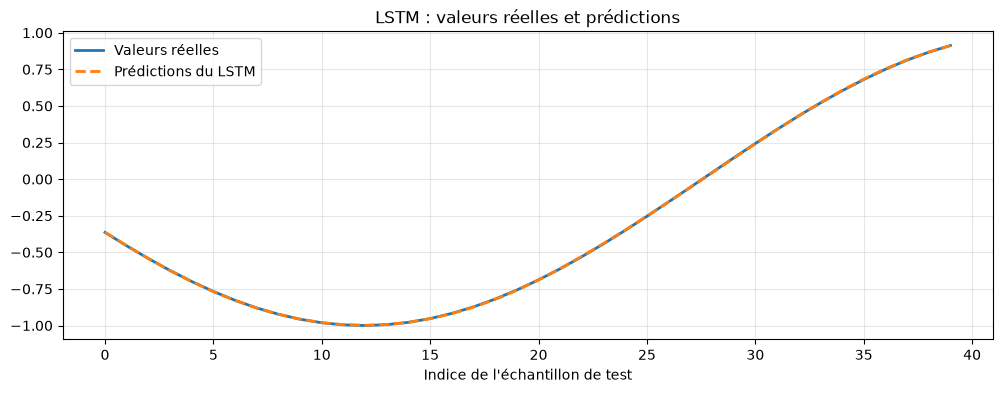

In [4]:
class SimpleLSTM(nn.Module):
    def __init__(self):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=16, num_layers=1, batch_first=True)
        self.sortie = nn.Linear(16, 1)

    def forward(self, x):
        etats, (h_final, c_final) = self.lstm(x)
        return self.sortie(etats[:, -1, :])


torch.manual_seed(42)
predictions, resultats["LSTM"] = entrainer(SimpleLSTM())
tracer(predictions, "LSTM")

## 4. Modèle Transformer

Projection 1 → 16, positional embedding, attention multi-têtes (2 têtes, dimension 16), Add & Norm, feed-forward 16 → 32 → 16 (ReLU), Add & Norm, dernière représentation, Linear 16 → 1.

Epoch  50 | Erreur : 0.001504
Epoch 100 | Erreur : 0.000110
Epoch 150 | Erreur : 0.000026
Epoch 200 | Erreur : 0.000012
Epoch 250 | Erreur : 0.000007
Epoch 300 | Erreur : 0.000004

Erreur de test : 0.000006
Valeur réelle  : -0.3639
Valeur prédite : -0.3662


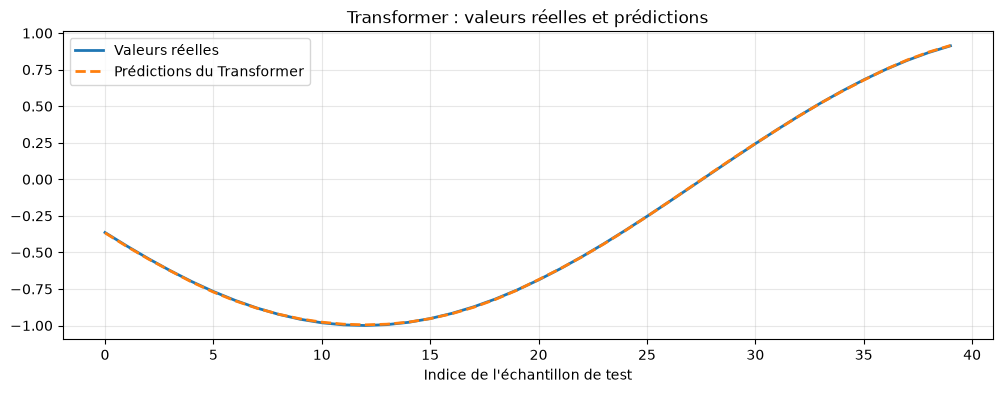

In [5]:
class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10, dimension=16):
        super().__init__()
        self.projection = nn.Linear(1, dimension)
        self.positions = nn.Embedding(longueur_max, dimension)

        couche = nn.TransformerEncoderLayer(
            d_model=dimension,
            nhead=2,
            dim_feedforward=32,
            dropout=0.0,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=1, enable_nested_tensor=False)
        self.sortie = nn.Linear(dimension, 1)

    def forward(self, x):
        indices = torch.arange(x.size(1), device=x.device)
        x = self.projection(x) + self.positions(indices).unsqueeze(0)   # (B, 10, 16)
        representations = self.encodeur(x)                               # (B, 10, 16)
        return self.sortie(representations[:, -1, :])                    # (B, 1)


torch.manual_seed(42)
predictions, resultats["Transformer"] = entrainer(MiniTransformer(longueur_max=longueur_sequence))
tracer(predictions, "Transformer")

In [6]:
print("Erreur MSE sur le test :")
for nom, erreur in resultats.items():
    print(f"  {nom:<12} {erreur:.6f}")

Erreur MSE sur le test :
  RNN          0.000028
  LSTM         0.000003
  Transformer  0.000006


**Comparaison :** sur cette sinusoïde, les trois modèles donnent une erreur de test très faible (MSE de l'ordre de 10⁻⁵ à 10⁻⁶) : LSTM ≈ 0,000003, Transformer ≈ 0,000006, RNN ≈ 0,000028. Le problème est simple et les séquences sont courtes (10 valeurs), donc le RNN suffit ; les avantages du LSTM et du Transformer apparaissent surtout sur des séquences longues.

## 5. Modèle de type GPT : prédire la suite d'un texte

In [7]:
from transformers import AutoTokenizer, AutoModelForCausalLM

tokenizer = AutoTokenizer.from_pretrained("gpt2")
modele_gpt = AutoModelForCausalLM.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
modele_gpt.eval()

texte = "Artificial intelligence can help people"
entrees = tokenizer(texte, return_tensors="pt")
print("Dimensions de l'entrée :", entrees["input_ids"].shape)

torch.manual_seed(42)
with torch.no_grad():
    sortie = modele_gpt.generate(
        **entrees,
        max_new_tokens=50,
        do_sample=True,
        temperature=0.8,
        top_p=0.9,
        pad_token_id=tokenizer.pad_token_id,
    )

print("\nTexte généré :")
print(tokenizer.decode(sortie[0], skip_special_tokens=True))

c:\Users\tmt\Desktop\TP4_Architecture_Transformer\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\tmt\Desktop\TP4_Architecture_Transformer\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\tmt\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In or

Dimensions de l'entrée : torch.Size([1, 6])

Texte généré :
Artificial intelligence can help people understand and understand a vast range of things, from our everyday lives to the everyday activities of others, and from our work. For this reason, we think it's important to understand what is and isn't possible.


## 6. Modèle de type BERT : prédire un mot masqué

In [8]:
from transformers import AutoModelForMaskedLM

tokenizer_bert = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")
modele_bert = AutoModelForMaskedLM.from_pretrained("bert-base-multilingual-cased")
modele_bert.eval()

texte = f"Rabat est la {tokenizer_bert.mask_token} du Maroc."
entrees = tokenizer_bert(texte, return_tensors="pt")
position_masque = (entrees["input_ids"][0] == tokenizer_bert.mask_token_id).nonzero(as_tuple=True)[0].item()

with torch.no_grad():
    logits = modele_bert(**entrees).logits

probabilites = torch.softmax(logits[0, position_masque], dim=-1)
top_p, top_i = torch.topk(probabilites, k=5)

print("Texte :", texte)
for p, i in zip(top_p, top_i):
    mot = tokenizer_bert.decode([i.item()]).strip()
    print(f"{p.item():.2%} | {texte.replace(tokenizer_bert.mask_token, mot)}")

c:\Users\tmt\Desktop\TP4_Architecture_Transformer\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\tmt\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 384.55it/s]
[transformers] Bert

Texte : Rabat est la [MASK] du Maroc.
86.06% | Rabat est la capitale du Maroc.
5.19% | Rabat est la ville du Maroc.
5.03% | Rabat est la préfecture du Maroc.
0.85% | Rabat est la Rabat du Maroc.
0.58% | Rabat est la capital du Maroc.


# Deuxième partie

## Exercice 1 : Prédiction de la consommation électrique avec un Transformer

Utiliser les 24 dernières heures de `Global_active_power` (moyenne horaire, en kW) pour prédire l'heure suivante.

### 1. Préparation des données

In [9]:
import copy
import numpy as np
import pandas as pd
from torch.utils.data import TensorDataset, DataLoader

df = pd.read_csv("household_power_consumption.txt", sep=";", na_values=["?"], low_memory=False)
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")

puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

moyenne = serie.iloc[:fin_train].mean()
ecart_type = serie.iloc[:fin_train].std()
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

fenetre = 24
X, y, dates_cibles = [], [], []
for i in range(fenetre, n):
    sequence = valeurs[i - fenetre:i]
    cible = valeurs[i]
    if np.isfinite(sequence).all() and np.isfinite(cible):
        X.append(sequence)
        y.append(cible)
        dates_cibles.append(i)

X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)
y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)
dates_cibles = np.array(dates_cibles)

train_mask = dates_cibles < fin_train
val_mask = (dates_cibles >= fin_train) & (dates_cibles < fin_val)
test_mask = dates_cibles >= fin_val

train_loader = DataLoader(TensorDataset(X[train_mask], y[train_mask]), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X[val_mask], y[val_mask]), batch_size=64)
test_loader = DataLoader(TensorDataset(X[test_mask], y[test_mask]), batch_size=64)

print("Heures :", n, "| de", serie.index[0], "à", serie.index[-1])
print("Heures manquantes :", int(serie.isna().sum()))
print(f"Moyenne train : {moyenne:.3f} kW | écart-type : {ecart_type:.3f} kW")
print("Fenêtres :", len(X), "| train :", int(train_mask.sum()), "| val :", int(val_mask.sum()), "| test :", int(test_mask.sum()))

Heures : 34589 | de 2006-12-16 17:00:00 à 2010-11-26 21:00:00
Heures manquantes : 438
Moyenne train : 1.086 kW | écart-type : 0.929 kW
Fenêtres : 33791 | train : 23805 | val : 5054 | test : 4932


### 2. Modèle EnergyTransformer

In [10]:
class EnergyTransformer(nn.Module):
    def __init__(self, fenetre=24, d_model=32):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(fenetre, d_model)

        couche = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=128,
            dropout=0.1,
            batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):
        indices = torch.arange(x.size(1), device=x.device)
        x = self.projection(x) + self.positions(indices).unsqueeze(0)   # (B, 24, 32)
        h = self.encodeur(x)                                             # (B, 24, 32)
        return self.sortie(h[:, -1, :])                                  # (B, 1)


torch.manual_seed(42)
modele_energie = EnergyTransformer(fenetre=fenetre)

xb, yb = next(iter(train_loader))
print("Entrée     :", xb.shape)
print("Projection :", modele_energie.projection(xb).shape)
print("Prédiction :", modele_energie(xb).shape)

Entrée     : torch.Size([64, 24, 1])
Projection : torch.Size([64, 24, 32])
Prédiction : torch.Size([64, 1])


### 3. Entraînement (Adam, lr = 0.001, MSE, 20 époques, meilleur modèle sur la validation)

Epoch  1 | train 0.4675 | val 0.4034  <- meilleur
Epoch  2 | train 0.4309 | val 0.4298
Epoch  3 | train 0.4241 | val 0.3917  <- meilleur
Epoch  4 | train 0.4166 | val 0.3845  <- meilleur
Epoch  5 | train 0.4169 | val 0.3895
Epoch  6 | train 0.4122 | val 0.3980
Epoch  7 | train 0.4095 | val 0.3884
Epoch  8 | train 0.4084 | val 0.3811  <- meilleur
Epoch  9 | train 0.4070 | val 0.3838
Epoch 10 | train 0.4047 | val 0.3861
Epoch 11 | train 0.4034 | val 0.3790  <- meilleur
Epoch 12 | train 0.4037 | val 0.3771  <- meilleur
Epoch 13 | train 0.3997 | val 0.3860
Epoch 14 | train 0.3983 | val 0.3796
Epoch 15 | train 0.3968 | val 0.3843
Epoch 16 | train 0.3972 | val 0.3853
Epoch 17 | train 0.3951 | val 0.3781
Epoch 18 | train 0.3934 | val 0.3893
Epoch 19 | train 0.3958 | val 0.3862
Epoch 20 | train 0.3923 | val 0.3882


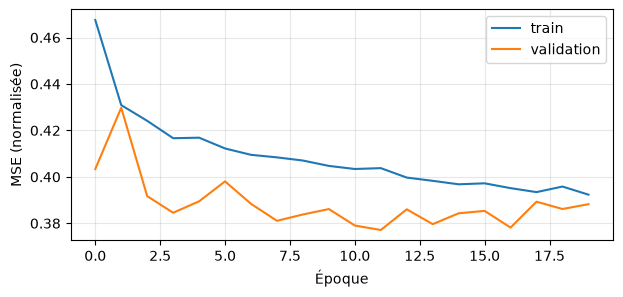

In [11]:
critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele_energie.parameters(), lr=0.001)


def perte_moyenne(modele, loader):
    modele.eval()
    total = 0.0
    with torch.no_grad():
        for xb, yb in loader:
            total += critere(modele(xb), yb).item() * len(xb)
    return total / len(loader.dataset)


meilleure_val = float("inf")
meilleur_etat = None
historique = []

for epoch in range(20):
    modele_energie.train()
    total = 0.0
    for xb, yb in train_loader:
        perte = critere(modele_energie(xb), yb)
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(xb)

    perte_train = total / len(train_loader.dataset)
    perte_val = perte_moyenne(modele_energie, val_loader)
    historique.append((perte_train, perte_val))

    if perte_val < meilleure_val:
        meilleure_val = perte_val
        meilleur_etat = copy.deepcopy(modele_energie.state_dict())
        marque = "  <- meilleur"
    else:
        marque = ""
    print(f"Epoch {epoch + 1:2d} | train {perte_train:.4f} | val {perte_val:.4f}{marque}")

modele_energie.load_state_dict(meilleur_etat)

plt.figure(figsize=(7, 3))
plt.plot([h[0] for h in historique], label="train")
plt.plot([h[1] for h in historique], label="validation")
plt.xlabel("Époque")
plt.ylabel("MSE (normalisée)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 4. Évaluation sur le test (en kW) et comparaison aux références

In [12]:
modele_energie.eval()
with torch.no_grad():
    pred_norm = torch.cat([modele_energie(xb) for xb, _ in test_loader]).squeeze(-1).numpy()

X_test_e, y_test_e = X[test_mask], y[test_mask]


def en_kw(v):
    return v * ecart_type + moyenne


reel = en_kw(y_test_e.squeeze(-1).numpy())
predictions_kw = {
    "Transformer": en_kw(pred_norm),
    "Persistance (h - 1)": en_kw(X_test_e[:, -1, 0].numpy()),
    "Journalière (h - 24)": en_kw(X_test_e[:, 0, 0].numpy()),
}

print(f"{'Modèle':<22}{'MAE (kW)':>10}{'RMSE (kW)':>11}")
for nom, p in predictions_kw.items():
    mae = np.mean(np.abs(p - reel))
    rmse = np.sqrt(np.mean((p - reel) ** 2))
    print(f"{nom:<22}{mae:>10.4f}{rmse:>11.4f}")

Modèle                  MAE (kW)  RMSE (kW)
Transformer               0.3358     0.4926
Persistance (h - 1)       0.3892     0.5884
Journalière (h - 24)      0.5133     0.7639


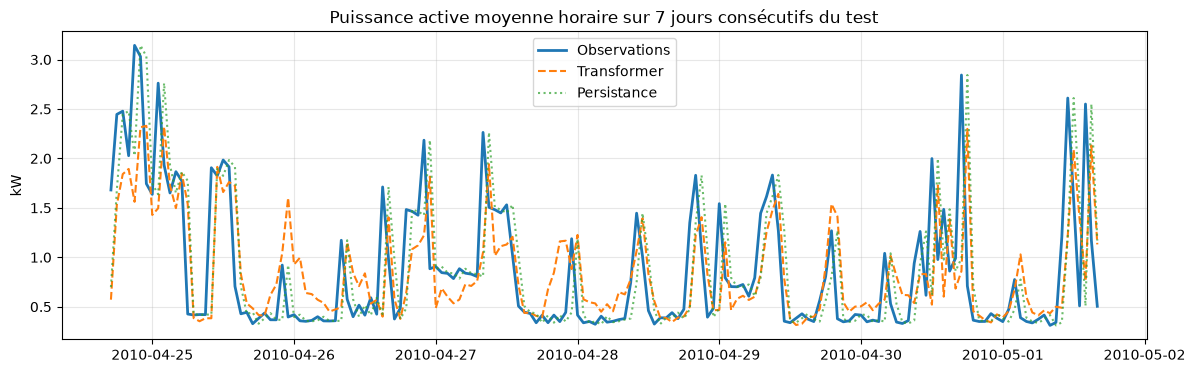

In [13]:
indices_test = dates_cibles[test_mask]
debut = next(k for k in range(len(indices_test) - 168)
             if indices_test[k + 167] - indices_test[k] == 167)
tranche = slice(debut, debut + 168)
heures = serie.index[indices_test[tranche]]

plt.figure(figsize=(14, 4))
plt.plot(heures, reel[tranche], label="Observations", linewidth=2)
plt.plot(heures, predictions_kw["Transformer"][tranche], "--", label="Transformer")
plt.plot(heures, predictions_kw["Persistance (h - 1)"][tranche], ":", label="Persistance", alpha=0.7)
plt.title("Puissance active moyenne horaire sur 7 jours consécutifs du test")
plt.ylabel("kW")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 5. Questions de réflexion

**Le Transformer améliore-t-il les deux références ?** Oui. Sur le test, il obtient une MAE de 0,336 kW et une RMSE de 0,493 kW, contre 0,389 / 0,588 kW pour la persistance et 0,513 / 0,764 kW pour la référence journalière. L'amélioration par rapport à la persistance est réelle (environ 14 % sur la MAE) mais modérée : la consommation de l'heure précédente reste un très bon prédicteur. La référence journalière est la plus mauvaise, car les habitudes d'un jour à l'autre varient beaucoup.

**Une fenêtre de 168 heures capturerait-elle mieux les habitudes hebdomadaires ?** Elle donnerait accès à la même heure de chaque jour de la semaine précédente, ce qui peut aider à distinguer semaine et week-end. En contrepartie, l'attention coûte beaucoup plus cher (24² = 576 paires contre 168² = 28 224), il y a plus de paramètres de position à apprendre, et davantage de fenêtres sont écartées à cause des valeurs manquantes. Le gain n'est pas garanti : il faudrait le mesurer sur la validation.

**Intérêt d'ajouter l'heure de la journée et le jour de la semaine ?** Avec seulement 24 valeurs, le modèle ne sait pas à quelle heure ni quel jour il se trouve. Ces variables calendaires (par exemple encodées en sinus/cosinus ou par des embeddings) lui donnent directement le contexte des habitudes : pics du soir, différences entre semaine et week-end. L'entrée passerait alors de 1 à plusieurs variables par heure.

**Pourquoi normaliser uniquement avec l'entraînement ?** Pour éviter une fuite d'information : la validation et le test doivent représenter des données futures inconnues. Calculer la moyenne et l'écart-type sur toute la série ferait entrer des informations du futur dans le modèle et rendrait l'évaluation trop optimiste.

**Comment prédire une énergie en kWh ?** L'énergie d'une heure est la somme des puissances minute par minute multipliées par la durée (1/60 h) : `puissance.resample("h").sum() / 60`, en ne gardant que les heures complètes (60 mesures) ou en corrigeant les minutes manquantes. Pour une heure complète, la puissance moyenne en kW est numériquement égale à l'énergie en kWh ; l'adaptation concerne donc surtout le traitement des heures incomplètes et le cumul sur des durées plus longues.

## Exercice 2 : Mini-GPT pour générer du texte (caractère par caractère)

In [14]:
with open("corpus.txt", encoding="utf-8") as fichier:
    texte = fichier.read()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
taille_vocabulaire = len(caracteres)

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

longueur = 64
coupure = int(0.9 * len(tokens))
tokens_train, tokens_val = tokens[:coupure], tokens[coupure:]

print("Caractères :", len(texte), "| vocabulaire :", taille_vocabulaire)
print("Exemple : entrée =", repr(texte[:6]), "-> cible =", repr(texte[1:7]))


def lot(source, batch=32):
    debuts = torch.randint(0, len(source) - longueur - 1, (batch,))
    x = torch.stack([source[d:d + longueur] for d in debuts])
    y = torch.stack([source[d + 1:d + longueur + 1] for d in debuts])
    return x, y

Caractères : 5575 | vocabulaire : 55
Exemple : entrée = "L'appr" -> cible = "'appre"


In [15]:
class BlocGPT(nn.Module):
    def __init__(self, d=64, tetes=4):
        super().__init__()
        self.ln1 = nn.LayerNorm(d)
        self.attention = nn.MultiheadAttention(d, tetes, dropout=0.2, batch_first=True)
        self.ln2 = nn.LayerNorm(d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d), nn.Dropout(0.2))

    def forward(self, x):
        T = x.shape[1]
        masque = torch.triu(torch.ones(T, T, dtype=torch.bool, device=x.device), diagonal=1)

        a = self.ln1(x)
        a, _ = self.attention(a, a, a, attn_mask=masque, need_weights=False)
        x = x + a                       # connexion résiduelle 1
        x = x + self.mlp(self.ln2(x))   # connexion résiduelle 2
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocabulaire, d=64, longueur_max=64, blocs=2, tetes=4):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocabulaire, d)
        self.positions = nn.Embedding(longueur_max, d)
        self.blocs = nn.Sequential(*[BlocGPT(d, tetes) for _ in range(blocs)])
        self.ln_finale = nn.LayerNorm(d)
        self.tete = nn.Linear(d, taille_vocabulaire)

    def forward(self, ids):
        T = ids.shape[1]
        x = self.tokens(ids) + self.positions(torch.arange(T, device=ids.device))
        x = self.blocs(x)
        return self.tete(self.ln_finale(x))


torch.manual_seed(42)
gpt = MiniGPT(taille_vocabulaire)

x, y = lot(tokens_train)
print("Identifiants :", x.shape)
print("Représentations :", (gpt.tokens(x) + gpt.positions(torch.arange(longueur))).shape)
print("Logits :", gpt(x).shape)
print("Cibles :", y.shape)

Identifiants : torch.Size([32, 64])
Représentations : torch.Size([32, 64, 64])
Logits : torch.Size([32, 64, 55])
Cibles : torch.Size([32, 64])


In [16]:
optimiseur = torch.optim.AdamW(gpt.parameters(), lr=3e-3)
critere = nn.CrossEntropyLoss()


@torch.no_grad()
def perte_val_gpt(n=20):
    gpt.eval()
    pertes = []
    for _ in range(n):
        x, y = lot(tokens_val)
        logits = gpt(x)
        pertes.append(critere(logits.reshape(-1, taille_vocabulaire), y.reshape(-1)).item())
    gpt.train()
    return sum(pertes) / n


meilleure_val, meilleur_etat = float("inf"), None

gpt.train()
for etape in range(1, 2001):
    x, y = lot(tokens_train)
    logits = gpt(x)
    perte = critere(logits.reshape(-1, taille_vocabulaire), y.reshape(-1))

    optimiseur.zero_grad()
    perte.backward()
    optimiseur.step()

    if etape % 50 == 0:
        perte_val = perte_val_gpt()
        if perte_val < meilleure_val:
            meilleure_val, meilleur_etat = perte_val, copy.deepcopy(gpt.state_dict())
        if etape % 250 == 0:
            print(f"Étape {etape:4d} | train {perte.item():.3f} | val {perte_val:.3f}")

gpt.load_state_dict(meilleur_etat)
print(f"\nMeilleure perte de validation conservée : {meilleure_val:.3f}")

Étape  250 | train 1.792 | val 2.132
Étape  500 | train 1.197 | val 2.068
Étape  750 | train 0.777 | val 2.410
Étape 1000 | train 0.597 | val 2.714
Étape 1250 | train 0.467 | val 2.865
Étape 1500 | train 0.442 | val 3.104
Étape 1750 | train 0.371 | val 3.250
Étape 2000 | train 0.357 | val 3.422

Meilleure perte de validation conservée : 2.036


In [17]:
@torch.no_grad()
def generer(amorce, n=200, temperature=1.0):
    gpt.eval()
    ids = torch.tensor([[stoi[c] for c in amorce]])
    for _ in range(n):
        logits = gpt(ids[:, -longueur:])[:, -1, :]
        probabilites = torch.softmax(logits / temperature, dim=-1)
        suivant = torch.multinomial(probabilites, num_samples=1)
        ids = torch.cat([ids, suivant], dim=1)
    return "".join(itos[i] for i in ids[0].tolist())


for temperature in (0.5, 1.0, 1.5):
    torch.manual_seed(0)
    print(f"===== Température {temperature} =====")
    print(generer("Le Transformer ", temperature=temperature))
    print()

===== Température 0.5 =====
Le Transformer les plus pons sortemps de mots et les mots et des de têtes au traisement ent les ent de têtemps, un paration de d'un paraînement coduent ent d'un traînempagation de de connée de de fonnées de tepagage

===== Température 1.0 =====
Le Transformer les, les mont sypeux recommet les vent la pregage haque de décére étite. Iliser unes.

Au Thaque un s'eme génentrampendentaînemaines.

Les résentatuse Trationstrellon paralèle rédiffére de de tepagage

===== Température 1.5 =====
Le Transformer les, loévéraris et iné cesuho sont pagesque exde.

à têteCT pentaînt réponsit mréioindanée frape un sentatte peuis. Au en PT.

GPT : Il ce les, put séqueramètste l'oure extrésentanuâce que Choi paquen



### Vérification : un caractère futur ne modifie pas les logits des positions précédentes

In [18]:
gpt.eval()
x, _ = lot(tokens_val, batch=1)
x_modifie = x.clone()
x_modifie[0, -1] = (x[0, -1] + 1) % taille_vocabulaire   # on change le dernier caractère

with torch.no_grad():
    l1, l2 = gpt(x), gpt(x_modifie)

print("Positions précédentes identiques :", torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-5))
print("Dernière position modifiée       :", not torch.allclose(l1[:, -1], l2[:, -1], atol=1e-5))

Positions précédentes identiques : True
Dernière position modifiée       : True


### Questions

**Observations :** le corpus est petit (5 575 caractères, 55 symboles). La perte d'entraînement continue de baisser (0,36), mais la perte de validation remonte après environ 500 étapes (de 2,07 à 3,42) : le modèle apprend le corpus par cœur. On a donc ajouté du dropout (0,2) et conservé le meilleur modèle sur la validation (perte 2,04). La vérification de causalité est validée : modifier le dernier caractère ne change pas les logits des positions précédentes.

**Que se passe-t-il si le masque causal est supprimé ?** Chaque position verrait le caractère suivant, qui est justement sa cible. Le modèle apprendrait à le recopier et la perte d'entraînement deviendrait très faible, mais il serait inutilisable en génération : à ce moment-là, le futur n'existe pas encore. Entraînement et génération ne correspondraient plus.

**Effet de la température :** les logits sont divisés par la température avant le softmax. À 0,5, la distribution est plus pointue : le modèle choisit les caractères les plus probables et produit des répétitions (« de de », « ent ent »). À 1,0, on échantillonne selon la distribution apprise. À 1,5, la distribution est aplatie : les caractères rares sont plus souvent choisis, et le texte devient plus varié mais incohérent (mots inventés, majuscules et ponctuation au hasard).

**Pourquoi décaler les cibles d'une position ?** La tâche est de prédire le caractère suivant : la cible de la position t est le caractère t + 1. Sans décalage, le modèle apprendrait simplement à recopier son entrée. Grâce au décalage et au masque causal, une séquence de 64 caractères fournit 64 exemples d'entraînement calculés en parallèle.

## Exercice 3 : Mini-BERT pour retrouver des mots masqués

In [19]:
import random

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
LONGUEUR_MAX = 32

random.seed(42)
sujets = ["le chat", "le chien", "la fille", "le garçon", "le professeur", "l'étudiant",
          "la voisine", "le technicien", "la mère", "le père"]
verbes = {
    "mange": ["une pomme", "du pain", "une orange", "du fromage", "une banane"],
    "lit": ["un livre", "le journal", "une lettre", "un roman", "le cours"],
    "répare": ["la machine", "le vélo", "la voiture", "le moteur", "la porte"],
    "regarde": ["la télévision", "le ciel", "un film", "la mer", "le tableau"],
    "boit": ["du café", "du thé", "de l'eau", "du lait", "du jus"],
}
lieux = ["dans la cuisine", "dans le jardin", "à l'école", "au bureau", "à la maison",
         "dans le salon", "au parc", "à l'atelier"]
moments = ["le matin", "le soir", "aujourd'hui", "chaque jour", "le dimanche"]

phrases = set()
while len(phrases) < 2500:
    verbe = random.choice(list(verbes))
    phrases.add(" ".join([random.choice(sujets), verbe, random.choice(verbes[verbe]),
                          random.choice(lieux), random.choice(moments)]))
phrases = sorted(phrases)
random.shuffle(phrases)

phrases_train, phrases_val = phrases[:2000], phrases[2000:]
print(len(phrases_train), "phrases d'entraînement |", len(phrases_val), "de validation")
print("Exemple :", phrases_train[0])

2000 phrases d'entraînement | 500 de validation
Exemple : le chien mange du fromage à la maison le dimanche


In [20]:
mots = sorted({m for p in phrases_train for m in p.split()})
vocab = {"[PAD]": PAD, "[UNK]": UNK, "[CLS]": CLS, "[SEP]": SEP, "[MASK]": MASK}
for m in mots:
    vocab[m] = len(vocab)
inverse = {i: m for m, i in vocab.items()}
taille_vocabulaire = len(vocab)


def encoder(phrase):
    ids = [CLS] + [vocab.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:LONGUEUR_MAX]
    return ids + [PAD] * (LONGUEUR_MAX - len(ids))


ids_train = torch.tensor([encoder(p) for p in phrases_train])
ids_val = torch.tensor([encoder(p) for p in phrases_val])

print("Vocabulaire :", taille_vocabulaire)
print("Phrase encodée :", " ".join(inverse[i] for i in ids_train[0].tolist()))

Vocabulaire : 68
Phrase encodée : [CLS] le chien mange du fromage à la maison le dimanche [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]


In [21]:
def masquer(input_ids, generateur=None):
    ordinaires = input_ids > MASK                       # exclut PAD, UNK, CLS, SEP, MASK
    tirage = torch.rand(input_ids.shape, generator=generateur)
    selection = (tirage < 0.15) & ordinaires

    # au moins une position sélectionnée par phrase
    for ligne in range(input_ids.shape[0]):
        if not selection[ligne].any():
            candidats = ordinaires[ligne].nonzero().squeeze(-1)
            choix = candidats[torch.randint(len(candidats), (1,), generator=generateur)]
            selection[ligne, choix] = True

    corrompu = input_ids.clone()
    r = torch.rand(input_ids.shape, generator=generateur)
    a_masquer = selection & (r < 0.8)
    a_remplacer = selection & (r >= 0.8) & (r < 0.9)            # les 10 % restants sont conservés

    corrompu[a_masquer] = MASK
    aleatoires = torch.randint(MASK + 1, taille_vocabulaire, input_ids.shape, generator=generateur)
    corrompu[a_remplacer] = aleatoires[a_remplacer]

    labels = input_ids.clone()
    labels[~selection] = -100
    return corrompu, labels, selection


c, l, s = masquer(ids_train[:1])
print("Original  :", " ".join(inverse[i] for i in ids_train[0].tolist() if i != PAD))
print("Corrompu  :", " ".join(inverse[i] for i in c[0].tolist() if i != PAD))
print("Proportion sélectionnée (train) :",
      round(masquer(ids_train)[2].sum().item() / (ids_train > MASK).sum().item(), 3))

Original  : [CLS] le chien mange du fromage à la maison le dimanche [SEP]
Corrompu  : [CLS] le [MASK] mange du fromage [MASK] la maison le [MASK] [SEP]
Proportion sélectionnée (train) : 0.173


In [22]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocabulaire, d=64, longueur_max=LONGUEUR_MAX):
        super().__init__()
        self.tokens = nn.Embedding(taille_vocabulaire, d, padding_idx=PAD)
        self.positions = nn.Embedding(longueur_max, d)
        couche = nn.TransformerEncoderLayer(d_model=d, nhead=4, dim_feedforward=4 * d,
                                            dropout=0.1, batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=2, enable_nested_tensor=False)
        self.ln = nn.LayerNorm(d)
        self.tete = nn.Linear(d, taille_vocabulaire)

    def forward(self, ids, masque_padding):
        T = ids.shape[1]
        x = self.tokens(ids) + self.positions(torch.arange(T, device=ids.device))
        x = self.encodeur(x, src_key_padding_mask=masque_padding)   # aucun masque causal
        return self.tete(self.ln(x))


torch.manual_seed(42)
bert = MiniBERT(taille_vocabulaire)
optimiseur = torch.optim.AdamW(bert.parameters(), lr=1e-3)
critere = nn.CrossEntropyLoss(ignore_index=-100)

g_val = torch.Generator().manual_seed(123)
val_corrompu, val_labels, val_selection = masquer(ids_val, g_val)


def exactitude_val():
    bert.eval()
    with torch.no_grad():
        logits = bert(val_corrompu, ids_val == PAD)
    predits = logits.argmax(-1)
    return (predits[val_selection] == ids_val[val_selection]).float().mean().item()


for epoch in range(1, 31):
    bert.train()
    corrompu, labels, _ = masquer(ids_train)          # nouveau masquage à chaque époque
    permutation = torch.randperm(len(corrompu))
    total = 0.0
    for debut in range(0, len(corrompu), 64):
        idx = permutation[debut:debut + 64]
        logits = bert(corrompu[idx], ids_train[idx] == PAD)
        perte = critere(logits.reshape(-1, taille_vocabulaire), labels[idx].reshape(-1))
        optimiseur.zero_grad()
        perte.backward()
        optimiseur.step()
        total += perte.item() * len(idx)
    if epoch % 5 == 0:
        print(f"Epoch {epoch:2d} | perte {total / len(corrompu):.3f} | exactitude val {exactitude_val():.1%}")

Epoch  5 | perte 1.272 | exactitude val 63.4%
Epoch 10 | perte 0.721 | exactitude val 71.3%
Epoch 15 | perte 0.659 | exactitude val 75.1%
Epoch 20 | perte 0.601 | exactitude val 73.8%
Epoch 25 | perte 0.557 | exactitude val 74.8%
Epoch 30 | perte 0.541 | exactitude val 76.4%


### Trois propositions les plus probables pour quelques mots masqués

In [23]:
bert.eval()
for phrase in phrases_val[:5]:
    ids = torch.tensor([encoder(phrase)])
    mots_phrase = phrase.split()
    position = random.Random(len(phrase)).randrange(len(mots_phrase)) + 1   # +1 pour [CLS]
    attendu = inverse[ids[0, position].item()]
    ids[0, position] = MASK

    with torch.no_grad():
        probas = torch.softmax(bert(ids, ids == PAD)[0, position], dim=-1)
    top_p, top_i = torch.topk(probas, 3)

    affichage = " ".join(inverse[i] for i in ids[0].tolist() if i not in (PAD, CLS, SEP))
    propositions = ", ".join(f"{inverse[i.item()]} ({p.item():.0%})" for p, i in zip(top_p, top_i))
    print(f"{affichage}\n   attendu : {attendu} | top 3 : {propositions}\n")

la voisine mange une pomme au [MASK] le soir
   attendu : bureau | top 3 : bureau (62%), parc (37%), l'atelier (0%)

[MASK] chat boit du thé dans la cuisine le soir
   attendu : le | top 3 : le (99%), la (0%), l'étudiant (0%)

le professeur regarde la télévision à la maison [MASK] matin
   attendu : le | top 3 : le (100%), la (0%), chaque (0%)

le technicien répare le [MASK] à l'atelier chaque jour
   attendu : vélo | top 3 : moteur (48%), vélo (47%), porte (1%)

[MASK] père boit du lait dans le salon le matin
   attendu : le | top 3 : le (100%), la (0%), chaque (0%)



### Vérification : modifier le padding ne change pas les prédictions des tokens utiles

In [24]:
bert.eval()
ids = val_corrompu[:8]
masque_padding = ids_val[:8] == PAD

ids_modifies = ids.clone()
aleatoires = torch.randint(MASK + 1, taille_vocabulaire, ids.shape)
ids_modifies[masque_padding] = aleatoires[masque_padding]

with torch.no_grad():
    l1 = bert(ids, masque_padding)
    l2 = bert(ids_modifies, masque_padding)

utiles = ~masque_padding
print("Prédictions des tokens utiles identiques :", torch.allclose(l1[utiles], l2[utiles], atol=1e-5))

Prédictions des tokens utiles identiques : True


### Questions

**Observations :** le corpus contient 2 500 phrases construites à partir de modèles (2 000 pour l'entraînement, 500 pour la validation, 68 mots). Après 30 époques, l'exactitude sur les tokens sélectionnés de la validation atteint environ 76 %. Le maximum n'est pas 100 % : le sujet, l'objet, le lieu et le moment sont tirés au hasard, donc plusieurs réponses sont souvent possibles (par exemple « moteur » 48 % et « vélo » 47 % pour « le technicien répare le [MASK] »). La proportion de positions sélectionnées est de 17 % au lieu de 15 %, car on impose au moins une position par phrase. La vérification du padding est validée.

**Pourquoi BERT peut-il utiliser le contexte à droite ?** C'est un encodeur sans masque causal : chaque position peut regarder toute la phrase. Le mot à prédire étant remplacé (par [MASK], un autre mot ou laissé tel quel sans que le modèle le sache), il ne peut pas recopier la réponse. Par exemple, pour « au [MASK] le soir », le modèle propose « bureau » ou « parc » : des lieux masculins compatibles avec « au ».

**Pourquoi calculer la perte uniquement sur les positions sélectionnées ?** Les autres tokens sont visibles en entrée : les prédire reviendrait à les recopier, une tâche triviale qui dominerait la perte. On inclut aussi les 10 % de tokens laissés inchangés, pour que le modèle ne puisse pas supposer qu'un mot visible est toujours correct : il doit construire une bonne représentation de chaque mot.

**Pourquoi ce modèle ne génère-t-il pas du texte comme GPT ?** Il n'a pas appris à prédire le mot suivant à partir du passé : il prédit un mot caché en voyant les deux côtés. Pour générer, il faudrait remplir des masques de façon itérative, sans ordre naturel ni moyen simple de décider de la longueur du texte. GPT, avec son attention causale, est entraîné exactement pour la génération mot après mot.